# 02 · Attention: letting the decoder look back at the English words

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/Translation-spanish-english/blob/master/notebooks/02_attention_and_its_heatmap.ipynb)

**What this notebook does.** Notebook 01 squeezed the whole English sentence into one state. Here we add **attention**: at every step the decoder may look back at *all* English words and decide which ones matter for the next Spanish word.
Everything else stays the same (data, split, vocabularies, sizes, training settings, test sentences), so that any difference in the numbers is caused by attention, and we draw the **attention heat map** to see what the decoder looks at.

*Time: about 45 minutes (the two training cells take about twelve minutes each on a laptop CPU). Prerequisite: notebook 01.*

## 1 · The big question

Notebook 01 ended with a weakness: the encoder's state has only 512 numbers, whatever the length of the sentence, and the BLEU score fell as sentences got longer (14.4, 12.0, 10.3).
**Can the decoder do better if, instead of one summary, it may consult every English word while it writes?**

> **Predict:** will attention help more for short or for long sentences? And will the heat map look like a diagonal line (word by word) or something else?

## 2 · Intuition first: a translator with the source text in front of her

In notebook 01 the interpreter listened to the whole sentence once and then had to speak from memory. Now she has the **written sentence in front of her** and can point a finger at the word she needs
for each word she writes: when she writes *cómo* she looks at *how*; when she writes *estás* she looks at *are* and *you*. She does not need to remember everything, she only needs to know *where to look*.

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once (and install sacrebleu).
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/Translation-spanish-english.git"], check=True)
    os.chdir("Translation-spanish-english/notebooks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sacrebleu"], check=True)

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import time
import numpy as np
import matplotlib.pyplot as plt

from src import translation as tr            # import before TensorFlow: it sets two environment variables
from src.translation import save_figure

tr.set_seed()                      # fixed seed (42): you should get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

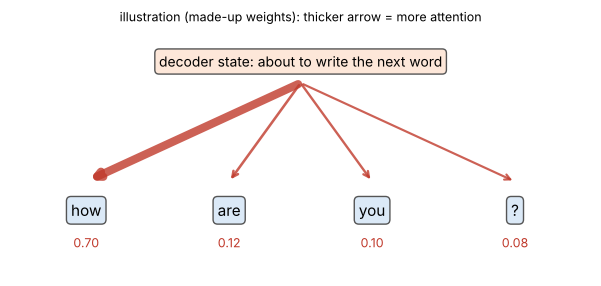

In [2]:
fig = tr.plot_attention_idea()
save_figure(fig, "02_attention_idea.png")
plt.show()

**What to notice.** The decoder (top) is about to write a word and gives a *weight* to each English word: here most of its attention (0.70) goes to *how*. The weights are positive and add up to 1.

*Figure: an illustration of attention with made-up weights.*

**Math (light).** At step $t$ the decoder has a state $q_t$ (the "query"); the encoder has one state $k_s$ for each English word $s$ (the "keys", which are also the "values" $v_s$ that we mix):

$$e_{ts}=q_t\cdot k_s \qquad \alpha_{ts}=\frac{\exp(e_{ts})}{\sum_{s'}\exp(e_{ts'})} \qquad c_t=\sum_s \alpha_{ts}\,v_s \qquad \text{next word}=\mathrm{softmax}\big(W\tanh(W_c[q_t;c_t])\big)$$

- $q_t\cdot k_s$: the dot product (multiply position by position and add): large when the decoder state and the English word's state point in a similar direction, so $e_{ts}$ is the *score* of English word $s$ at step $t$;
- $\alpha_{ts}$: the **attention weight**: the scores turned into positive numbers that add up to 1 over the English words (softmax); the heat map below shows exactly these numbers;
- $c_t$: the **context vector**: the English states mixed with the weights;
- $[q_t;c_t]$: the decoder state and the context glued together; $W_c$ and $W$ are learned weights; the result is the probabilities of the next word, as in notebook 01.

Padding positions (the zeros that fill short sentences) are *masked*: they get weight 0, so the decoder never looks at filling.

## 3 · Same data, same split, same settings

The code below is the same as in notebook 01 (the split, the vocabularies and the arrays are identical, the test sentences are the same 2,000). To make the comparison exact we also **re-train the baseline of notebook 01 here** with the same seed and settings:
it should reproduce notebook 01's numbers (validation losses, BLEU 11.2).

In [3]:
import keras

pairs = tr.load_pairs()
train, validation, test = tr.make_split(pairs)
train_pairs, validation_pairs, test_pairs = tr.flatten(train), tr.flatten(validation), tr.flatten(test)
source_vocab = tr.Vocabulary([tr.tokenize(e) for e, _ in train_pairs], 6000)
target_vocab = tr.Vocabulary([tr.tokenize(s) for _, s in train_pairs], 8000)

source, decoder_in, decoder_out = tr.encode_pairs(train_pairs, source_vocab, target_vocab)
val_source, val_decoder_in, val_decoder_out = tr.encode_pairs(validation_pairs, source_vocab, target_vocab)
test_english = list(test)
test_source, _, _ = tr.encode_pairs([(e, "") for e in test_english], source_vocab, target_vocab)
references = [test[e] for e in test_english]
print(f"train {len(train_pairs):,} pairs, validation {len(validation_pairs):,} pairs, test {len(test_english):,} English sentences; vocabularies {len(source_vocab):,} / {len(target_vocab):,}")

def train_model(builder, label):
    tr.set_seed()
    model, encoder, decoder = builder(len(source_vocab), len(target_vocab), embedding=128, units=256)
    model.compile(optimizer=keras.optimizers.Adam(2e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    start = time.time()
    history = model.fit([source, decoder_in], decoder_out, batch_size=128, epochs=12,
                        validation_data=([val_source, val_decoder_in], val_decoder_out), callbacks=[stop], verbose=0).history
    print(f"{label}: {model.count_params():,} parameters, trained for {len(history['loss'])} epochs in {time.time() - start:.0f} s")
    print("   validation loss per epoch:", [round(v, 2) for v in history["val_loss"]])
    return encoder, decoder, history

train 30,001 pairs, validation 2,424 pairs, test 2,000 English sentences; vocabularies 6,000 / 8,000


In [4]:
base_encoder, base_decoder, base_history = train_model(tr.build_seq2seq, "without attention (the baseline of notebook 01)")

without attention (the baseline of notebook 01): 4,636,480 parameters, trained for 12 epochs in 705 s
   validation loss per epoch: [4.13, 3.8, 3.51, 3.25, 3.04, 2.9, 2.77, 2.67, 2.6, 2.53, 2.49, 2.45]


**What to notice.** The validation losses are those of notebook 01 (4.13, 3.8, 3.51, ... 2.45), as they should be: same data, same seed, same settings. Now the model with attention.

In [5]:
att_encoder, att_decoder, att_history = train_model(tr.build_attention_seq2seq, "with attention")

with attention: 4,767,808 parameters, trained for 12 epochs in 775 s
   validation loss per epoch: [2.9, 2.55, 2.26, 2.05, 1.81, 1.6, 1.46, 1.36, 1.32, 1.28, 1.27, 1.28]


**What to notice.**

- The baseline reproduces notebook 01 exactly: the same 12 validation losses (4.13 ... 2.45), the same parameter count (4,636,480) and the same time (about twelve minutes). Same data, same seed, same settings give the same numbers.
- The attention model has 4,767,808 parameters, only 131,328 more (2.8%; the layer that combines the decoder state with the context), and trained about 10% longer (775 s against 705 s).
- **Its validation loss is far lower from the very first epoch** (2.90 after one epoch, where the baseline needs six epochs to get there) and reaches 1.27 at epoch 11 (1.28 at epoch 12; the weights of the best epoch, 11, are kept), against 2.45 for the baseline. The attention model learns much faster and goes much further in the same twelve epochs.

In [6]:
start = time.time()
base_hyp = tr.translate(base_encoder, base_decoder, test_source, target_vocab)
att_hyp, att_maps = tr.translate_with_attention(att_encoder, att_decoder, test_source, target_vocab)
print(f"translated {len(test_english):,} sentences with both models in {time.time() - start:.0f} s\n")

def exact(hyps):
    return np.mean([" ".join(h) in [" ".join(tr.tokenize(r)) for r in refs] for h, refs in zip(hyps, references)])

rows = {"without attention": base_hyp, "with attention": att_hyp}
print(f"{'':20s} {'BLEU':>6s} {'exact match':>12s}")
for name, hyps in rows.items():
    print(f"{name:20s} {tr.corpus_bleu(hyps, references):6.1f} {exact(hyps):12.1%}")

translated 2,000 sentences with both models in 10 s

                       BLEU  exact match


without attention      11.2         1.8%
with attention         25.8         8.8%


**What to notice.** On the same 2,000 unseen test sentences, **BLEU rises from 11.2 to 25.8** and the exact match rate from 1.8% to 8.8%. (BLEU is computed as in notebook 01: lower-cased text split into words and punctuation marks, all available references, so the numbers are only comparable with each other.)

BLEU(with attention) - BLEU(without): +14.6
paired bootstrap over the test sentences (200 resamples): 95% interval +13.4 to +15.8;  share of resamples in which attention is better: 100%
1-4 words     159 sentences   without  14.4   with attention  25.5
5-7 words    1092 sentences   without  12.0   with attention  27.6


8-10 words    749 sentences   without  10.3   with attention  24.1


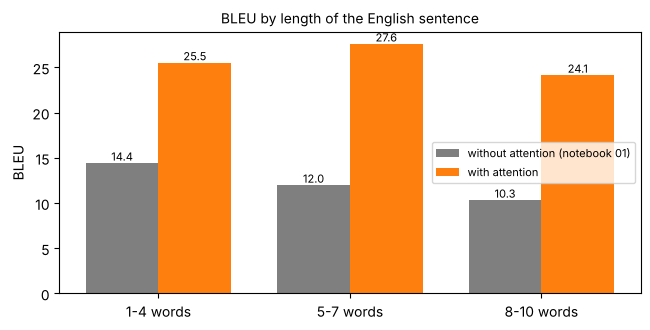

In [7]:
differences = tr.bootstrap_bleu_difference(att_hyp, base_hyp, references, resamples=200)
low, high = np.percentile(differences, [2.5, 97.5])
print(f"BLEU(with attention) - BLEU(without): {tr.corpus_bleu(att_hyp, references) - tr.corpus_bleu(base_hyp, references):+.1f}")
print(f"paired bootstrap over the test sentences (200 resamples): 95% interval {low:+.1f} to {high:+.1f};  share of resamples in which attention is better: {np.mean(differences > 0):.0%}")

groups = [("1-4 words", 1, 4), ("5-7 words", 5, 7), ("8-10 words", 8, 10)]
base_scores, att_scores = [], []
for label, lo, hi in groups:
    index = [i for i, e in enumerate(test_english) if lo <= len(tr.tokenize(e)) <= hi]
    base_scores.append(tr.corpus_bleu([base_hyp[i] for i in index], [references[i] for i in index]))
    att_scores.append(tr.corpus_bleu([att_hyp[i] for i in index], [references[i] for i in index]))
    print(f"{label:11s} {len(index):5d} sentences   without {base_scores[-1]:5.1f}   with attention {att_scores[-1]:5.1f}")

fig = tr.plot_bleu_comparison([g[0] for g in groups], base_scores, att_scores)
save_figure(fig, "02_bleu_by_length.png")
plt.show()

**What to notice.**

- The paired bootstrap resamples the *test sentences* 200 times and recomputes both scores on each resample: the difference is **+14.6 BLEU, with a 95% interval of +13.4 to +15.8, and attention is ahead in all 200 resamples**. The interval only reflects which test sentences were drawn; it does not include the variation between training runs (we trained each model once, with one seed), so it is a reason to trust the *size* of the gap, not a full significance test.
- Attention is better for **every length group** (25.5, 27.6 and 24.1 against 14.4, 12.0 and 10.3). Without attention the score falls steadily as sentences get longer; with attention it stays high, and the biggest gain is not for the longest group (+11.1 for 1-4 words, +15.6 for 5-7, +13.8 for 8-10). So the picture matches the bottleneck idea only in part: attention helps at all lengths.
- Fairness: the attention model has 2.8% more parameters and took about 10% more time to train; this is far too little to explain a doubling of the score.

*Figure: BLEU by length of the English sentence, without and with attention.*

In [8]:
for english, reference, a, b in list(zip(test_english, references, base_hyp, att_hyp))[:8]:
    print(f"EN  : {english}\nREF : {reference[0]}\nbase: {' '.join(a)}\natt : {' '.join(b)}\n")

EN  : I bought two pairs of trousers.
REF : Compré dos pares de pantalones.
base: compré dos libros de la .
att : compré dos de detectives .

EN  : Tom died from tuberculosis.
REF : Tom murió de tuberculosis.
base: tom murió en el .
att : tom murió de la mano .

EN  : Will it be hot again tomorrow?
REF : ¿Mañana volverá a hacer calor?
base: ¿ de verdad te bien ?
att : ¿ usted calor mañana ?

EN  : I don't know how to swim.
REF : No sé nadar.
base: no sé cómo .
att : no sé cómo nadar .

EN  : Tom stabbed Mary repeatedly with his knife.
REF : Tom apuñaló a Mary repetidamente con su cuchillo.
base: tom ayudó a mary con su padre .
att : tom le mostró a mary con sus cuchillo .

EN  : I don't remember inviting you.
REF : No recuerdo haberte invitado.
base: no me acuerdo con él .
att : no me acuerdo de .

EN  : Where did you buy this motorcycle?
REF : ¿Dónde compraste esta moto?
base: ¿ dónde aprendiste a tu auto ?
att : ¿ dónde compraste esta moto ?

EN  : What else do you want to do?
REF : 

**What to notice.** With attention some sentences are now translated exactly like a reference (*¿Dónde compraste esta moto?* and *¿Qué más quieres hacer?*), and others are much closer (*no sé cómo nadar* against *no sé cómo* for the baseline). Errors remain: *compré dos de detectives* (the pairs of trousers became "of detectives"), *tom murió de la mano* ("tuberculosis" became "the hand") and a grammar slip in *con sus cuchillo*.
So the model now follows the English sentence word by word, but a small vocabulary and few training pairs still produce wrong words and wrong grammar.

### Check yourself

1. The attention weights of one decoding step add up to 1. What would it mean if a weight were exactly 1?
2. Why must the padding positions be masked?

<details>
<summary>Answers</summary>


1. The decoder would use only that single English word for the next Spanish word (a "hard" choice); the context vector would be just that word's state.
2. The padding positions contain no word; without a mask the softmax would still give them weight, and the decoder would mix "nothing" into its context.

</details>

## 4 · What does the decoder look at? The attention heat map

For the translations the model made, we collect the weights $\alpha_{ts}$ at every step. **Rows** are the Spanish words the model wrote, **columns** the English words; a darker cell means more attention.
We show the first four test sentences of 5 to 8 tokens in the fixed test order (chosen by this rule, not by how well they were translated). The heat map shows what the model *did*, whether or not the translation is good.

EN: I bought two pairs of trousers.   ->   ES: compré dos de detectives .
EN: Tom died from tuberculosis.   ->   ES: tom murió de la mano .
EN: Will it be hot again tomorrow?   ->   ES: ¿ usted calor mañana ?
EN: Tom stabbed Mary repeatedly with his knife.   ->   ES: tom le mostró a mary con sus cuchillo .


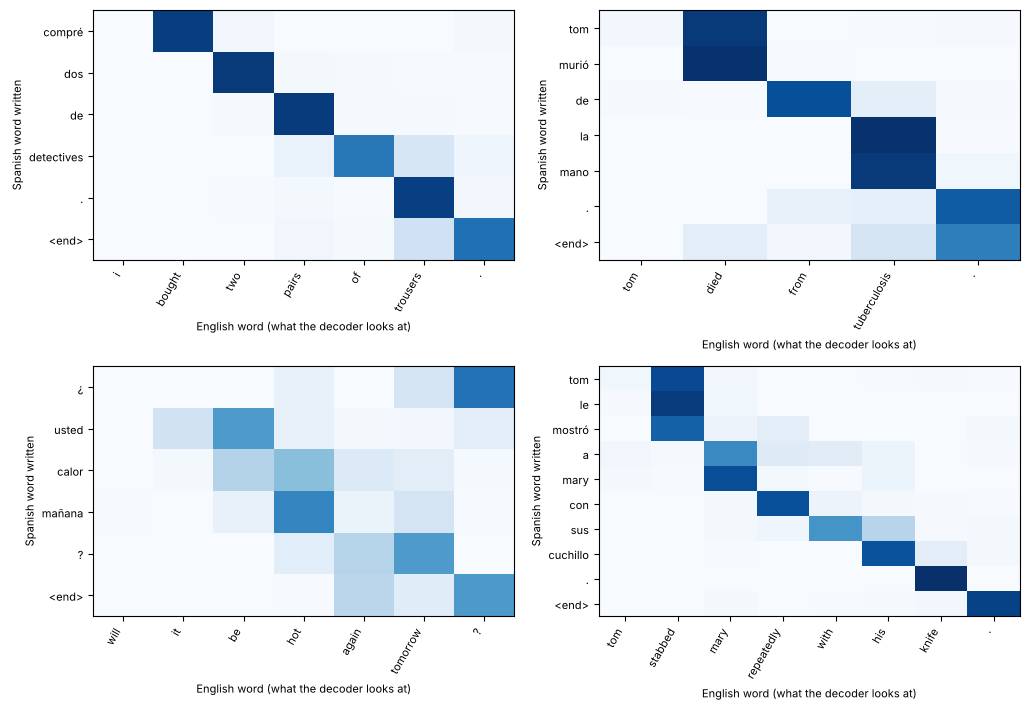

In [9]:
shown = [i for i, e in enumerate(test_english) if 5 <= len(tr.tokenize(e)) <= 8][:4]
items = []
for i in shown:
    english_tokens = tr.tokenize(test_english[i])
    spanish_tokens = att_hyp[i] + ["<end>"]
    weights = att_maps[i][:len(spanish_tokens), :len(english_tokens)]
    items.append((english_tokens, spanish_tokens[:len(weights)], weights))
    print(f"EN: {test_english[i]}   ->   ES: {' '.join(att_hyp[i])}")

fig = tr.plot_attention_maps(items)
save_figure(fig, "02_attention_heatmaps.png")
plt.show()

**What to notice.** Rows are the Spanish words written, columns the English words.

- **Mostly a diagonal:** for *I bought two pairs of trousers* (top left) and *Tom stabbed Mary repeatedly with his knife* (bottom right) the decoder moves along the English sentence roughly word by word: *compré* looks at *bought*, *dos* at *two*, *mary* at *mary*, *cuchillo* at *knife*.
- **Not only a diagonal:** for the question *Will it be hot again tomorrow?* (bottom left) the first Spanish word *¿* looks at the *?* at the **end** of the English sentence, a useful non-monotonic jump: the opening question mark is predicted from the closing one. The attention for *calor* and *mañana* is spread over *be*, *hot* and *tomorrow* and is less sharp.
- **Looking at the right word does not make it right:** in *Tom died from tuberculosis* the words *la mano* look at *tuberculosis* but the model writes the wrong Spanish for it.
- **Caution:** an LSTM encoder state at a word also contains the words before it. When *tom* and *le* in the bottom-right map look at *stabbed*, the information about *tom* is probably in that state too, so a heat map must not be read as "the decoder ignores all other words".

*Figure: attention heat maps of four test translations (the first four test sentences with 5 to 8 words in the fixed test order).*

In [10]:
# how focused is the attention? over all test sentences: the largest weight per step and the entropy relative to a uniform spread
largest, relative_entropy = [], []
for english, weights in zip(test_english, att_maps):
    n = len(tr.tokenize(english))
    real = weights[:, :n]
    largest.extend(real.max(axis=1))
    if n > 1:
        entropy = -(real * np.log(real + 1e-12)).sum(axis=1)
        relative_entropy.extend(entropy / np.log(n))
print(f"average largest attention weight per step: {np.mean(largest):.2f}")
print(f"average entropy relative to a uniform spread over the English words (1.0 = no focus at all): {np.mean(relative_entropy):.2f}")
print(f"share of steps where one English word gets more than half of the attention: {np.mean(np.array(largest) > 0.5):.0%}")

average largest attention weight per step: 0.76
average entropy relative to a uniform spread over the English words (1.0 = no focus at all): 0.35
share of steps where one English word gets more than half of the attention: 86%


**What to notice.** The attention is **focused**: on average the largest weight of a step is 0.76, the entropy is 35% of what an even spread over the English words would give, and in 86% of the steps one English word gets more than half of the attention. The decoder usually looks at one or two words, not at the whole sentence.

## 5 · Common mistakes

- **Reading the heat map as a proof of "why".** Attention weights show where the model gathered information; they are not a complete explanation (other parts of the network also matter).
- **Forgetting the mask.** Without it the model attends to padding.
- **Comparing models trained differently.** Here everything but attention is identical, including the seed; even so one training run per model is a small sample (see the bootstrap above, which resamples the *test sentences*, not the training runs).
- **Using teacher-forced attention maps.** With the correct previous words as input the maps look better than at translation time; we plot the maps of the model's own translations.

## 6 · Recap

- Attention gives the decoder a weight for every English word at every step, so the sentence no longer has to pass through one small state.
- The heat map shows where the decoder looks; the quantitative comparison (BLEU, by length, with a bootstrap) says whether it helped.
- Both models are small and not fully trained: the numbers are a baseline for the last step, a pretrained model.

**Next:** notebook 03 compares with a pretrained translation model on the same test sentences (if one can be obtained in the environment).